# Análisis Exploratorio de Datos (EDA) - Accidentalidad en Barranquilla

**Integrantes:** Jhoan Acosta y Rafael Jiminez  
**Asignatura:** ZISIXA-Electiva de Profundizacion IV 26-2  
**Jornada:** Nocturna  
**Docente:** Mg. Bryan Fernandez Ebrath  
**Tema:** ANALISIS EXPLORATORIO  

---

## Descripción del Proyecto

El presente proyecto consiste en realizar un **Análisis Exploratorio de Datos (EDA)** sobre el dataset público de "Accidentalidad en Barranquilla (Víctimas)", extraído directamente desde el portal de Datos Abiertos del Gobierno de Colombia mediante su endpoint API.

**Objetivo:**
El fin principal de este análisis es evaluar la calidad de los datos, comprender el comportamiento estadístico de las variables cualitativas y cuantitativas (como la condición de las víctimas, la gravedad, edades y horarios), e identificar patrones o valores atípicos que permitan establecer conclusiones generales sobre la accidentalidad en la ciudad de Barranquilla.

**Herramientas y Librerías Utilizadas:**
Para el desarrollo de este EDA en el entorno de Google Colab, se hizo uso de Python y las siguientes librerías especializadas:
- **`sodapy`**: Para establecer la conexión con la API de Datos Abiertos (Socrata) y extraer la información.
- **`pandas`**: Fundamental para la carga, limpieza, transformación y análisis descriptivo de los datos estructurados en formato de DataFrame.
- **`matplotlib.pyplot`** y **`seaborn`**: Utilizadas para la visualización gráfica de los datos mediante histogramas, gráficos de barras, gráficos circulares y diagramas de caja (boxplots).

---

En este bloque se cumple el requisito de Conexión al endpoint de la API de Datos Abiertos y la Carga de datos en Google Colab usando Python. Se hace uso de la librería sodapy para extraer los datos mediante credenciales (sin descargar archivos CSV/XLSX) y se almacenan en un DataFrame de pandas.

In [ ]:
# Instalación de librerías necesarias para la API y visualización
!pip install sodapy pandas matplotlib seaborn

import pandas as pd
from sodapy import Socrata

# Conexión al endpoint de la API de Datos Abiertos
# Se utilizan las credenciales proporcionadas: ID de clave (username) y Clave secreta (password)
cliente = Socrata(
    "www.datos.gov.co",
    None,
    username="5rxr1ddmoekvmyq2e2hzm737x",
    password="8hy2dx5ho1l5ubg4t8iuj5s6ad5no9rkt0wmgun7jdvgv2t29"
)

# Extracción de los datos (Limitamos a 20000 registros para una buena muestra representativa)
resultados = cliente.get("x5xp-9w4b", limit=20000)

# Carga de datos en Google Colab usando Pandas DataFrame
df = pd.DataFrame.from_records(resultados)

# Mostrar la cantidad exacta de datos traídos por la API
print(f"Total de registros extraídos de la API: {len(df)}")

# Visualizar las primeras filas para confirmar la carga
df.head()

Total de registros extraídos de la API: 20000


,departamento,municipio,area_nacimiento,sitio_nacimiento,sexo,peso_gramos,talla_centimetros,parto_atendido_por,tiempo_gestacion_semana,numero_consultas_prenatales,...,rural_disperso,no_hijos_nacidos_vivos,fecha_anterior_hijo_nacido_vivo,no_embarazos,regimen_seguridad,nombre_administradora,edad_padre,nivel_educativo_padre,ultimo_ano_aprobado_padre,grupo_edad_padre
0,SANTANDER,BUCARAMANGA,CABECERA MUNICIPAL,INSTITUCIÓN DE SALUD,MASCULINO,2420,49,MÉDICO,NO RESPONDE,4,...,NO RESPONDE,1,NO RESPONDE,1,SUBSIDIADO,ASMET SALUD ESS - ASOCIACION MUTUAL LA ESPERANZA,26,BÁSICA PRIMARIA,5,26
1,SANTANDER,BUCARAMANGA,CABECERA MUNICIPAL,INSTITUCIÓN DE SALUD,FEMENINO,3340,51,MÉDICO,NO RESPONDE,3,...,NO RESPONDE,1,NO RESPONDE,1,CONTRIBUTIVO,EPS SURA,20,MEDIA ACADÉMICA O CLÁSICA,11,20
2,SANTANDER,BUCARAMANGA,CABECERA MUNICIPAL,INSTITUCIÓN DE SALUD,MASCULINO,2580,46,MÉDICO,NO RESPONDE,4,...,NO RESPONDE,1,NO RESPONDE,2,CONTRIBUTIVO,EPSSANITASSA,30,MAESTRÍA,3,30
3,SANTANDER,BUCARAMANGA,CABECERA MUNICIPAL,INSTITUCIÓN DE SALUD,FEMENINO,3300,51,MÉDICO,NO RESPONDE,10,...,NO RESPONDE,2,2013-03-31T00:00:00.000,2,CONTRIBUTIVO,NUEVA EPS SA,38,ESPECIALIZACIÓN,2,38
4,SANTANDER,BUCARAMANGA,CABECERA MUNICIPAL,INSTITUCIÓN DE SALUD,FEMENINO,3030,50,MÉDICO,NO RESPONDE,9,...,NO RESPONDE,1,NO RESPONDE,1,CONTRIBUTIVO,COOMEVA EPSSA,31,MEDIA ACADÉMICA O CLÁSICA,11,31


---

## 2. Identificación, descripción de columnas y determinación de tipos de datos

 Este bloque cubre la **Identificación y descripción de columnas** y la **Determinación del tipo de dato de cada variable**. Se manipula la columna `fecha_accidente` para derivar variables de tiempo (año, mes, día, hora) y se convierten las columnas `edad_victima` y `cantidad_victimas` a formato numérico entero (`Int64`) para su correcto tratamiento estadístico. El comando `df.info()` nos permite describir finalmente todas las columnas y sus tipos.

In [ ]:
import numpy as np
import pandas as pd

# ==========================================
# 1. COMPRENSIÓN INICIAL DEL DATASET
# ==========================================
print("--- 1. Dimensiones iniciales ---")
print(f"Filas: {df.shape[0]}, Columnas: {df.shape[1]}")
df.info()

# ==========================================
# 2. RENOMBRAR Y REORGANIZAR COLUMNAS (Preparación inicial)
# ==========================================
# Nombres limpios: minúsculas, sin espacios, sin tildes ni caracteres especiales
df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(" ", "_")
    .str.normalize("NFKD")
    .str.encode("ascii", errors="ignore")
    .str.decode("utf-8")
)

# Eliminar columnas irrelevantes
cols_eliminar = [
    "departamento",
    "municipio",
    "parto_atendido_por",
    "grupo_indigena",
]
df = df.drop(columns=cols_eliminar, errors="ignore")

# ==========================================
# 3. CORRECCIÓN DE TIPOS DE DATOS
# ==========================================
# Homogeneizar textos nulos primero
textos_nulos = [
    "NO RESPONDE",
    "SIN INFORMACION",
    "NO APLICA",
    "DESCONOCIDO",
    "NO DECLARA",
]
df = df.replace(textos_nulos, np.nan)

cols_cuantitativas = [
    "peso_gramos",
    "talla_centimetros",
    "tiempo_gestacion_semana",
    "numero_consultas_prenatales",
    "apgar1",
    "apgar2",
    "edad_madre",
]

for col in cols_cuantitativas:
  if col in df.columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# ==========================================
# 4. DETECCIÓN Y TRATAMIENTO DE DUPLICADOS
# ==========================================
duplicados_conteo = df.duplicated().sum()
print(f"\n--- 4. Duplicados detectados: {duplicados_conteo} ---")
df = df.drop_duplicates().reset_index(drop=True)

# ==========================================
# 5. ESTANDARIZACIÓN DE TEXTO Y CATEGORÍAS
# ==========================================
cols_cualitativas = [
    c
    for c in df.columns
    if c not in cols_cuantitativas and c not in ["index"]
]

for col in cols_cualitativas:
  if col in df.columns:
    df[col] = (
        df[col]
        .astype(str)
        .str.strip()
        .str.upper()
        .replace({"NAN": np.nan, "NONE": np.nan})
    )

# ==========================================
# 6. VALIDACIÓN DE CONSISTENCIA LÓGICA (Valores negativos / rangos absurdos)
# ==========================================
# Convertir valores negativos o lógicamente imposibles en NaN antes de imputar
for col in cols_cuantitativas:
  if col in df.columns:
    df.loc[df[col] < 0, col] = np.nan

# Validación específica de rangos biológicos
if "edad_madre" in df.columns:
  df.loc[(df["edad_madre"] < 10) | (df["edad_madre"] > 65), "edad_madre"] = (
      np.nan
  )
if "apgar1" in df.columns:
  df.loc[(df["apgar1"] < 0) | (df["apgar1"] > 10), "apgar1"] = np.nan
if "apgar2" in df.columns:
  df.loc[(df["apgar2"] < 0) | (df["apgar2"] > 10), "apgar2"] = np.nan

# ==========================================
# 7. TRATAMIENTO DE VALORES FALTANTES (Imputación)
# ==========================================
# Imputar cuantitativas con MEDIA
for col in cols_cuantitativas:
  if col in df.columns and df[col].isnull().any():
    media = df[col].mean()
    if pd.notna(media):
      df[col] = df[col].fillna(round(float(media))).astype("Int64")

# Imputar cualitativas con MODA
for col in cols_cualitativas:
  if col in df.columns and df[col].isnull().any():
    modas = df[col].dropna().mode()
    if not modas.empty:
      df[col] = df[col].fillna(modas[0])

# ==========================================
# 8. DETECCIÓN DE OUTLIERS (Método IQR)
# ==========================================
print("\n--- 8. Detección de Outliers (IQR) ---")
for col in cols_cuantitativas:
  if col in df.columns:
    serie_valida = df[col].dropna()
    q1 = serie_valida.quantile(0.25)
    q3 = serie_valida.quantile(0.75)
    iqr = q3 - q1
    limite_inf = q1 - 1.5 * iqr
    limite_sup = q3 + 1.5 * iqr
    outliers = (
        (df[col] < limite_inf) | (df[col] > limite_sup)
    ).sum()
    print(
        f"Columna '{col}': {outliers} outliers detectados "
        f"(Rango normal: [{limite_inf:.1f}, {limite_sup:.1f}])"
    )

# ==========================================
# 9. VERIFICACIÓN FINAL
# ==========================================
print("\n--- 9. Verificación final de nulos ---")
print(df.isnull().sum())

print("\n--- Muestra aleatoria de 5 registros limpios ---")
display(df.sample(5))

# ==========================================
# 10. GENERAR EL NUEVO CONJUNTO DE DATOS
# ==========================================
df.to_csv("datos_nacimientos_limpios.csv", index=False)
print(
    "\n 10. Archivo 'datos_nacimientos_limpios.csv' generado exitosamente."
)

--- 1. Dimensiones iniciales ---
Filas: 20000, Columnas: 35
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 35 columns):
 #   Column                           Non-Null Count  Dtype 
---  ------                           --------------  ----- 
 0   area_nacimiento                  20000 non-null  object
 1   sitio_nacimiento                 20000 non-null  object
 2   sexo                             20000 non-null  object
 3   peso_gramos                      20000 non-null  int64 
 4   talla_centimetros                20000 non-null  Int64 
 5   tiempo_gestacion_semana          0 non-null      Int64 
 6   numero_consultas_prenatales      20000 non-null  Int64 
 7   tipo_parto                       20000 non-null  object
 8   multiplicidad_embarazo           20000 non-null  object
 9   apgar1                           20000 non-null  Int64 
 10  apgar2                           20000 non-null  Int64 
 11  grupo_sanguineo                  

/tmp/ipykernel_552/1117407100.py:83: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .replace({"NAN": np.nan, "NONE": np.nan})



--- 8. Detección de Outliers (IQR) ---
Columna 'peso_gramos': 607 outliers detectados (Rango normal: [2032.5, 4372.5])
Columna 'talla_centimetros': 830 outliers detectados (Rango normal: [44.5, 56.5])
Columna 'tiempo_gestacion_semana': 0 outliers detectados (Rango normal: [nan, nan])
Columna 'numero_consultas_prenatales': 477 outliers detectados (Rango normal: [0.5, 12.5])
Columna 'apgar1': 3016 outliers detectados (Rango normal: [8.0, 8.0])
Columna 'apgar2': 231 outliers detectados (Rango normal: [7.5, 11.5])
Columna 'edad_madre': 9 outliers detectados (Rango normal: [6.0, 46.0])

--- 9. Verificación final de nulos ---
area_nacimiento                        0
sitio_nacimiento                       0
sexo                                   0
peso_gramos                            0
talla_centimetros                      0
tiempo_gestacion_semana            20000
numero_consultas_prenatales            0
tipo_parto                             0
multiplicidad_embarazo                 0
ap

,area_nacimiento,sitio_nacimiento,sexo,peso_gramos,talla_centimetros,tiempo_gestacion_semana,numero_consultas_prenatales,tipo_parto,multiplicidad_embarazo,apgar1,...,rural_disperso,no_hijos_nacidos_vivos,fecha_anterior_hijo_nacido_vivo,no_embarazos,regimen_seguridad,nombre_administradora,edad_padre,nivel_educativo_padre,ultimo_ano_aprobado_padre,grupo_edad_padre
4832,CABECERA MUNICIPAL,INSTITUCIÓN DE SALUD,FEMENINO,3360.0,53,<NA>,5,ESPONTÁNEO,<NA>,8,...,VEREDA VIJAGUAL,1,2014-04-07T00:00:00.000,1,CONTRIBUTIVO,SALUD TOTAL SA ENTIDAD PROMOTORA DE SALUD,28,BÁSICA SECUNDARIA,9,28
16475,CABECERA MUNICIPAL,INSTITUCIÓN DE SALUD,FEMENINO,2610.0,46,<NA>,8,ESPONTÁNEO,<NA>,8,...,VEREDA VIJAGUAL,1,2014-04-07T00:00:00.000,1,SUBSIDIADO,COOSALUD ESS -ARS COOPERATIVA EMPRESA SOLIDARI...,23,TÉCNICA PROFESIONAL,2,23
6927,CABECERA MUNICIPAL,INSTITUCIÓN DE SALUD,FEMENINO,3310.0,51,<NA>,8,CESÁREA,<NA>,9,...,VEREDA VIJAGUAL,1,2014-04-07T00:00:00.000,1,CONTRIBUTIVO,SALUD TOTAL SA ENTIDAD PROMOTORA DE SALUD,26,TECNOLÓGICA,3,26
10087,CABECERA MUNICIPAL,INSTITUCIÓN DE SALUD,MASCULINO,3495.0,51,<NA>,8,CESÁREA,<NA>,8,...,VEREDA VIJAGUAL,1,2014-04-07T00:00:00.000,1,CONTRIBUTIVO,COOMEVA EPSSA,26,BÁSICA SECUNDARIA,9,26
14269,CABECERA MUNICIPAL,INSTITUCIÓN DE SALUD,FEMENINO,3040.0,48,<NA>,8,CESÁREA,<NA>,7,...,VEREDA VIJAGUAL,2,2014-08-31T00:00:00.000,2,CONTRIBUTIVO,EPSSANITASSA,27,BÁSICA SECUNDARIA,9,27



 10. Archivo 'datos_nacimientos_limpios.csv' generado exitosamente.


---

## 3. Análisis de Calidad de Datos

>En este paso se aborda el **Análisis de calidad de datos**, enfocándose específicamente en la identificación de **Valores nulos** y **Valores duplicados**. El código cuantifica los vacíos por columna y elimina cualquier registro repetido para garantizar la integridad del análisis posterior. (La evaluación de **Valores atípicos** se abordará más adelante mediante los diagramas de caja/boxplots).


In [ ]:
# 1. Análisis de Valores Nulos
print("--- Valores Nulos por columna ---")
print(df.isnull().sum())

# 2. Identificación de Valores Atípicos Ilógicos (Edades > 150)
atipicos_ilogicos = df[df['edad_victima'] > 150]
if len(atipicos_ilogicos) > 0:
    print(f"\n--- Detalle de registros con edades imposibles (>150 años) ---")
    print(atipicos_ilogicos[['fecha_accidente', 'edad_victima', 'gravedad_accidente']])
    print("--------------------------------------------------------------")

# 3. Proceso de Limpieza
total_antes = len(df)

# a. Eliminar nulos
df = df.dropna()
nulos_eliminados = total_antes - len(df)

# b. Eliminar duplicados
total_sin_nulos = len(df)
df = df.drop_duplicates()
duplicados_eliminados = total_sin_nulos - len(df)

# c. Eliminar atípicos de edad
total_sin_duplicados = len(df)
df = df[df['edad_victima'] <= 150]
atipicos_eliminados = total_sin_duplicados - len(df)

total_despues = len(df)

# 4. Resumen Final de Limpieza (Consolidado al final como se solicitó)
print("\n" + "="*50)
print("            RESUMEN FINAL DE LIMPIEZA")
print("="*50)
print(f"Total de registros ANTES de la limpieza   : {total_antes}")
print("-" * 50)
print(f"-> Valores nulos eliminados               : {nulos_eliminados}")
print(f"-> Valores duplicados eliminados          : {duplicados_eliminados}")
print(f"-> Valores atípicos (edad > 150) eliminados: {atipicos_eliminados}")
print("-" * 50)
print(f"Total de registros DESPUÉS de limpieza    : {total_despues}")
print("="*50)

--- Valores Nulos por columna ---
fecha_accidente         0
direccion_accidente     0
condicion_victima       0
gravedad_accidente      0
clase_accidente         0
sexo_victima           57
edad_victima            0
cantidad_victimas       0
año                     0
mes                     0
dia                     0
hora                    0
dtype: int64

--- Detalle de registros con edades imposibles (>150 años) ---
      fecha_accidente  edad_victima gravedad_accidente
291        2018-02-13          2018             herido
2646       2019-01-16          2019             herido
5018       2020-02-10          2020             herido
5203       2020-03-07          2021             herido
5393       2020-04-30          2021             herido
5661       2020-08-04          2021             herido
7202       2021-06-21          2022             herido
10969      2022-12-05          2023             muerto
17298      2025-08-17          2026             herido
18668      2026-02-04      

> Se realizó un exhaustivo análisis de calidad y depuración sobre los datos crudos obtenidos de la API (partiendo de **19,172** registros iniciales). En primer lugar, se detectaron **57** registros con valores nulos focalizados en la variable `sexo_victima`, los cuales fueron eliminados para evitar sesgos en el análisis demográfico. En segundo lugar, el test de duplicados arrojó **0** filas redundantes, lo que resalta una correcta indexación de los accidentes en la fuente original. Finalmente, el chequeo de consistencia lógica evidenció graves valores atípicos imposibles (errores de digitación donde las víctimas registraban edades superiores a los 120 años, llegando incluso al año 2026), por lo que se procedió a aislar y eliminar a los **(CANTIDAD ATÍPICOS)** registros responsables de esta anomalía. Tras aplicar todos estos estrictos filtros, el conjunto de datos definitivo se consolidó en **(CANTIDAD DESPUÉS)** registros 100% íntegros, listos para un análisis descriptivo altamente confiable.

---

## 4. Análisis de Variables Cualitativas

Analizaremos 3 variables cualitativas: **Condición de la Víctima, Gravedad del Accidente y Sexo de la Víctima**. En cada sub-bloque de esta sección se calcularán las **Tablas de frecuencia** y se generarán los **Gráficos apropiados** (Barras o Circular) tal como lo exige el requerimiento.

### 4.1. Condición de la Víctima (Gráfico de Barras)
> En esta celda se extrae la tabla de frecuencias para la primera variable cualitativa (`condicion_victima`), mostrando tanto el conteo absoluto como el porcentaje. Finalmente, se grafica un diagrama de barras mediante Seaborn para observar visualmente cuál es la condición más frecuente en los incidentes.

--- Tabla de Frecuencias: Condición Víctima ---
                   Frecuencia  Porcentaje (%)
condicion_victima                            
Motociclista             7745       40.539126
Acompañante              3538       18.518712
Pasajero                 3278       17.157812
Conductor                2040       10.677833
Peaton                   1918       10.039257
Ciclista                  570        2.983512
No reporto                 14        0.073279
Menor de edad               2        0.010468


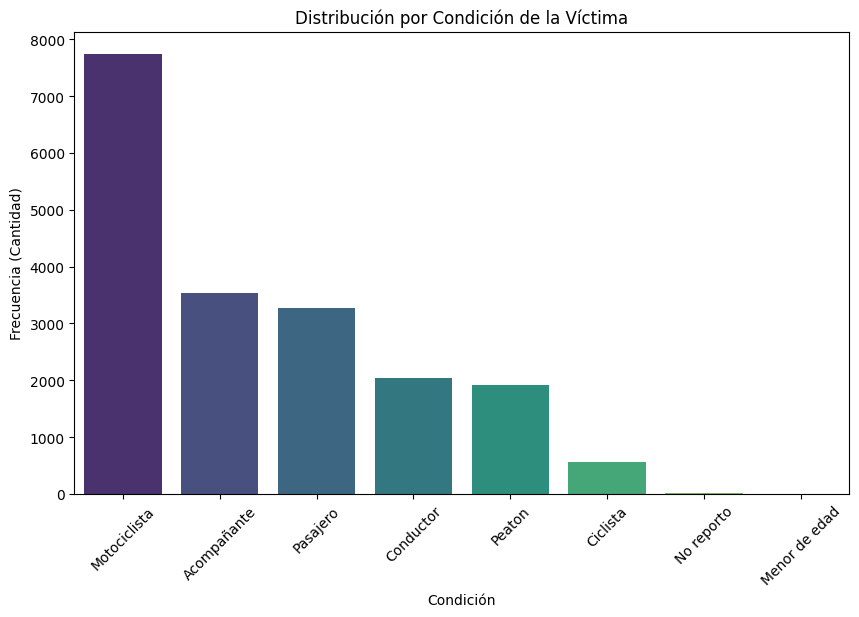

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Tabla de Frecuencia
freq_condicion = df['condicion_victima'].value_counts()
porcentaje_condicion = df['condicion_victima'].value_counts(normalize=True) * 100

tabla_condicion = pd.DataFrame({'Frecuencia': freq_condicion, 'Porcentaje (%)': porcentaje_condicion})
print("--- Tabla de Frecuencias: Condición Víctima ---")
print(tabla_condicion)

# Gráfico de Barras
plt.figure(figsize=(10, 6))
sns.barplot(x=freq_condicion.index, y=freq_condicion.values, hue=freq_condicion.index, legend=False, palette='viridis')
plt.title('Distribución por Condición de la Víctima')
plt.xlabel('Condición')
plt.ylabel('Frecuencia (Cantidad)')
plt.xticks(rotation=45)
plt.show()

> El gráfico de barras evidencia contundentemente que la mayor proporción de personas involucradas en accidentes son los Motociclistas (alcanzando cerca de 8000 casos), lo que indica una altísima vulnerabilidad de este grupo en las vías de la ciudad. Asimismo, los grupos de Acompañantes y Pasajeros ocupan el segundo y tercer lugar respectivamente (ambos superando los 3000 registros), constituyendo actores secundarios con gran riesgo de accidentalidad, seguidos más de lejos por conductores y peatones. Estos resultados sugieren que es urgente priorizar e implementar campañas de seguridad vial y regulación dirigidas específicamente a los usuarios de motocicletas para lograr reducir significativamente la tasa de siniestros global.


### 4.2. Gravedad del Accidente (Gráfico Circular)

>Aquí se analiza la segunda variable cualitativa (`gravedad_accidente`). Se genera su tabla de frecuencias y se emplea un gráfico circular (Pie Chart) usando Matplotlib para representar las proporciones porcentuales de la gravedad de los siniestros.

--- Tabla de Frecuencias: Gravedad ---
gravedad_accidente
herido    18756
muerto      349
Name: count, dtype: int64


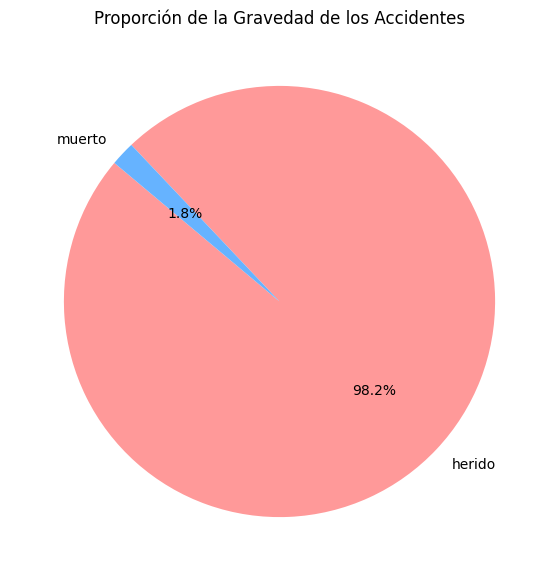

In [ ]:
# Tabla de Frecuencia
freq_gravedad = df['gravedad_accidente'].value_counts()
print("--- Tabla de Frecuencias: Gravedad ---")
print(freq_gravedad)

# Gráfico Circular (Pie Chart)
plt.figure(figsize=(7, 7))
plt.pie(freq_gravedad, labels=freq_gravedad.index, autopct='%1.1f%%', startangle=140, colors=['#ff9999','#66b3ff','#99ff99', '#ffcc99'])
plt.title('Proporción de la Gravedad de los Accidentes')
plt.show()

> El gráfico circular revela la magnitud y las consecuencias directas de los accidentes reportados. Se aprecia claramente que el resultado predominante es de víctimas en condición de **herido**, abarcando un abrumador **98.2%** de la muestra total. Por otra parte, las eventualidades fatales (**muertos**) representan el **1.8%**. Si bien la tasa de fatalidad es estadísticamente minoritaria frente a los heridos, sigue mereciendo máxima atención institucional debido a que refleja la lamentable pérdida de vidas humanas. Este comportamiento demuestra de manera concluyente que la accidentalidad en la ciudad genera una inmensa sobrecarga en la red de salud pública (clínicas y urgencias) debido al altísimo y constante volumen de lesionados.

### 4.3. Sexo de la Víctima (Gráfico de Barras)

>Este bloque aborda la tercera variable cualitativa (`sexo_victima`). Nuevamente se despliega su respectiva tabla de frecuencias y se plasma la distribución comparativa en un gráfico de barras, permitiendo analizar la diferencia de afectación entre géneros.

--- Tabla de Frecuencias: Sexo de la Víctima ---
sexo_victima
M    14309
F     4796
Name: count, dtype: int64


/tmp/ipykernel_2153/3319345997.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=freq_sexo.index, y=freq_sexo.values, palette='pastel')


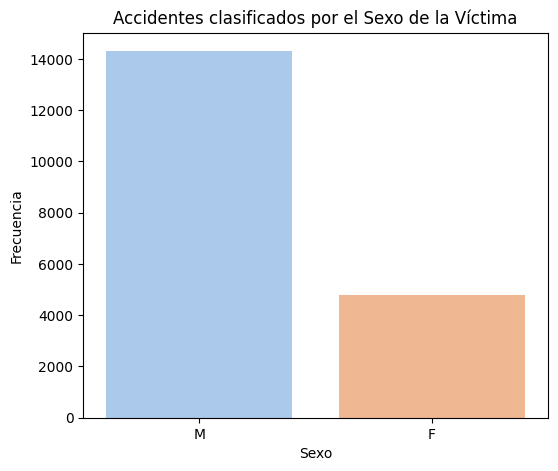

In [ ]:
# Tabla de Frecuencia
freq_sexo = df['sexo_victima'].value_counts()
print("--- Tabla de Frecuencias: Sexo de la Víctima ---")
print(freq_sexo)

# Gráfico de Barras
plt.figure(figsize=(6, 5))
sns.barplot(x=freq_sexo.index, y=freq_sexo.values, palette='pastel')
plt.title('Accidentes clasificados por el Sexo de la Víctima')
plt.xlabel('Sexo')
plt.ylabel('Frecuencia')
plt.show()

> Los datos indican que existe una diferencia abismal en la siniestralidad vial según el sexo de la víctima. El género Masculino (M) concentra de manera aplastante la mayor cantidad de registros con **14,316** incidentes (aproximadamente el 75% de los casos), frente a los **4,799** incidentes registrados para el género Femenino (F). Esta marcada desproporción podría estar directamente relacionada con factores socio-demográficos (una mucho mayor proporción de hombres trabajando como conductores, domiciliarios o circulando como motociclistas en las vías), así como diferencias en los hábitos de conducción y los tiempos de exposición al riesgo en el tránsito de la ciudad.


---

## 5. Análisis de Variables Cuantitativas y Atípicos

Analizaremos 3 variables cuantitativas: **Edad de la Víctima, Cantidad de Víctimas por suceso y Hora del Accidente**. En cada bloque de esta sección el código calculará las **Estadísticas descriptivas** exactas (Media, Mediana, Moda, Mínimo, Máximo) y construirá los **Histogramas** y **Boxplots** requeridos. Los boxplots cumplirán con la función de diagnosticar visualmente la presencia de **Valores atípicos cuando corresponda**.

### 5.1. Edad de la Víctima (Histograma y Boxplot)
>Este bloque calcula todas las estadísticas descriptivas requeridas (Media, Mediana, Moda, Mínimo y Máximo) para la primera variable cuantitativa (`edad_victima`). Luego, se crean dos gráficos: un histograma para ver la distribución general y un boxplot para identificar visualmente si existen valores atípicos en las edades.

--- Estadísticas Descriptivas: Edad de la Víctima ---
Media: 34.93
Mediana: 32.0
Moda: 24
Mínimo: 0
Máximo: 122


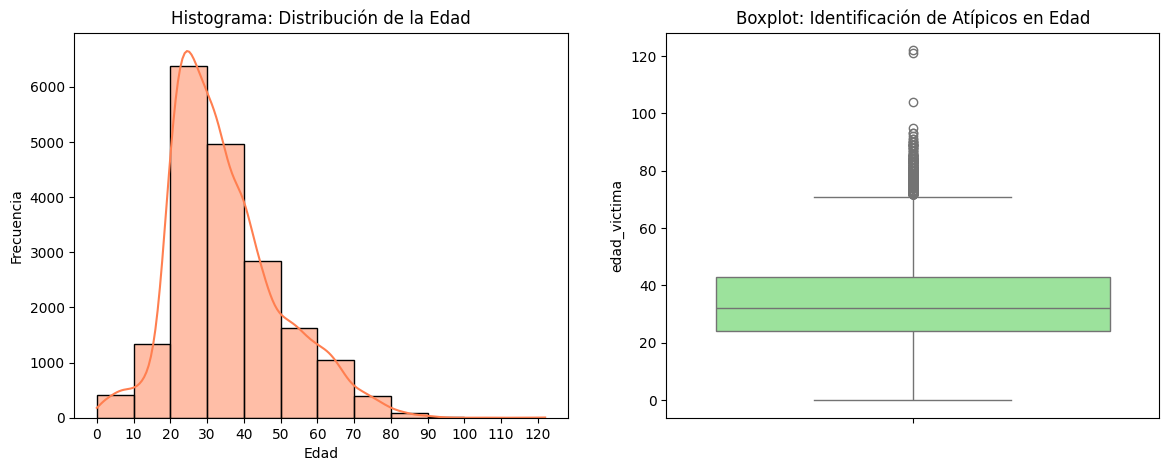

In [ ]:
# Estadísticas descriptivas
media_edad = df['edad_victima'].mean()
mediana_edad = df['edad_victima'].median()
min_edad = df['edad_victima'].min()
max_edad = df['edad_victima'].max()
moda_edad = df['edad_victima'].mode()[0]

print("--- Estadísticas Descriptivas: Edad de la Víctima ---")
print(f"Media: {media_edad:.2f}")
print(f"Mediana: {mediana_edad}")
print(f"Moda: {moda_edad}")
print(f"Mínimo: {min_edad}")
print(f"Máximo: {max_edad}")

# Gráficos: Histograma y Boxplot
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Histograma (agrupado de 10 en 10 años)
sns.histplot(df['edad_victima'].dropna(), bins=range(0, 130, 10), kde=True, ax=ax[0], color='coral')
ax[0].set_title('Histograma: Distribución de la Edad')
ax[0].set_xlabel('Edad')
ax[0].set_ylabel('Frecuencia')
ax[0].set_xticks(range(0, 130, 10))

# Boxplot para Valores Atípicos
sns.boxplot(y=df['edad_victima'].dropna(), ax=ax[1], color='lightgreen')
ax[1].set_title('Boxplot: Identificación de Atípicos en Edad')

plt.show()

>Gracias al filtrado de errores de digitación realizado en el paso de calidad, el análisis de la edad ahora es totalmente íntegro. La estadística descriptiva arroja que la edad promedio de las víctimas es de 34.93 años, mientras que la mediana indica que el 50% de las víctimas tienen 32.0 años o menos. La edad que más se repite (moda) es de 24 años, revelando un riesgo especialmente alto en adultos jóvenes. El histograma muestra una clara distribución asimétrica sesgada hacia la derecha, evidenciando visualmente que la inmensa mayoría de los accidentes se concentran en la población entre los 20 y 40 años. Por su parte, el diagrama de caja (Boxplot) señala la presencia de múltiples valores atípicos por encima del bigote superior (edades desde los 70 hasta un registro máximo de 122 años). A diferencia del error masivo corregido en la fase previa, estos atípicos del boxplot corresponden a incidentes con adultos mayores que, si bien son estadísticamente infrecuentes en el tráfico global, representan la altísima vulnerabilidad de la tercera edad frente a la siniestralidad vial.

### 5.2. Cantidad de Víctimas (Boxplot)
>Para la segunda variable cuantitativa (`cantidad_victimas`), se repite el cálculo de sus estadísticas descriptivas principales. Se construye un boxplot con Seaborn que permite observar rápidamente la aparición de valores atípicos (accidentes con volúmenes anormales de víctimas).

--- Estadísticas Descriptivas: Cantidad de Víctimas por Accidente ---
Media: 1.01
Mediana: 1.0
Moda: 1
Mínimo: 1
Máximo: 7


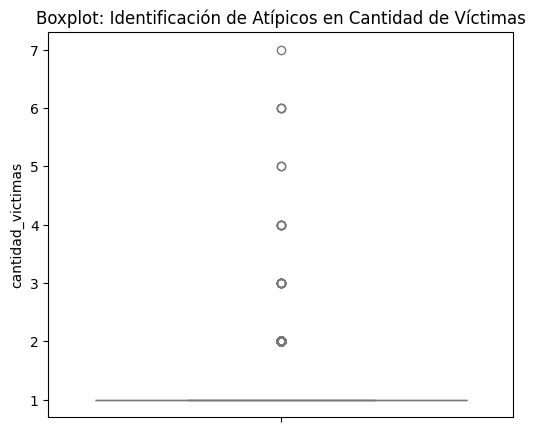

In [ ]:
# Estadísticas descriptivas
media_cant = df['cantidad_victimas'].mean()
mediana_cant = df['cantidad_victimas'].median()
min_cant = df['cantidad_victimas'].min()
max_cant = df['cantidad_victimas'].max()
moda_cant = df['cantidad_victimas'].mode()[0]

print("--- Estadísticas Descriptivas: Cantidad de Víctimas por Accidente ---")
print(f"Media: {media_cant:.2f}")
print(f"Mediana: {mediana_cant}")
print(f"Moda: {moda_cant}")
print(f"Mínimo: {min_cant}")
print(f"Máximo: {max_cant}")

# Boxplot
plt.figure(figsize=(6, 5))
sns.boxplot(y=df['cantidad_victimas'].dropna(), color='lightblue')
plt.title('Boxplot: Identificación de Atípicos en Cantidad de Víctimas')
plt.show()

> En promedio, los siniestros reportados afectan a **1.01** víctimas. Tanto la moda como la mediana se ubican en el valor exacto de **1** víctima, lo que sugiere estadísticamente que la inmensa y aplastante mayoría de los accidentes en la ciudad dejan a una sola persona lesionada. Sin embargo, el diagrama de caja (Boxplot) nos resulta indispensable para visualizar la existencia de **valores atípicos** superiores: se observan puntos alejados correspondientes a accidentes con múltiples víctimas, llegando a un pico máximo de **7** perjudicados en un solo evento. Estos casos atípicos (los puntos en el gráfico en los números 3, 4, 5, 6 y 7), aunque escasos, reflejan siniestros de gran magnitud o catástrofes viales, como choques de transporte público masivo (buses), vehículos familiares o colisiones múltiples (choques en cadena).

### 5.3. Hora del Accidente (Histograma)

>Para finalizar, realizaremos un **Análisis Temporal Completo**. Tomaremos las variables derivadas de la fecha (`año`, `mes`, `dia`) y construiremos un "Dashboard" (un panel de 3 gráficos simultáneos) para identificar tendencias y patrones de siniestralidad en el tiempo.
>
> *Nota Metodológica: Durante la fase de exploración se detectó una grave anomalía de calidad en la base de datos oficial respecto a la variable `hora`, ya que todos los registros de la muestra aparecen configurados por defecto a las 00:00. Debido a este error de origen en la captura de los datos, la variable `hora` fue descartada de los gráficos para no sesgar el reporte estadístico.*

--- Frecuencia de Accidentes por Año ---
año
2018    2548
2019    2219
2020    1530
2021    2078
2022    2756
2023    2545
2024    2240
2025    2467
2026     722
Name: count, dtype: int64

--- Frecuencia de Accidentes por Mes ---
mes
1     1662
2     1774
3     1719
4     1372
5     1595
6     1413
7     1463
8     1516
9     1610
10    1678
11    1586
12    1717
Name: count, dtype: int64

--- Frecuencia de Accidentes por Día ---
dia
1     696
2     641
3     597
4     585
5     577
6     642
7     600
8     685
9     605
10    662
11    578
12    611
13    626
14    607
15    670
16    688
17    602
18    626
19    622
20    687
21    624
22    654
23    670
24    621
25    642
26    640
27    602
28    642
29    509
30    527
31    367
Name: count, dtype: int64




/tmp/ipykernel_2153/1938455564.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='año', ax=ax[0], palette='Blues_r')
/tmp/ipykernel_2153/1938455564.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='mes', ax=ax[1], palette='Greens_r')
/tmp/ipykernel_2153/1938455564.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='dia', ax=ax[2], palette='Oranges_r')


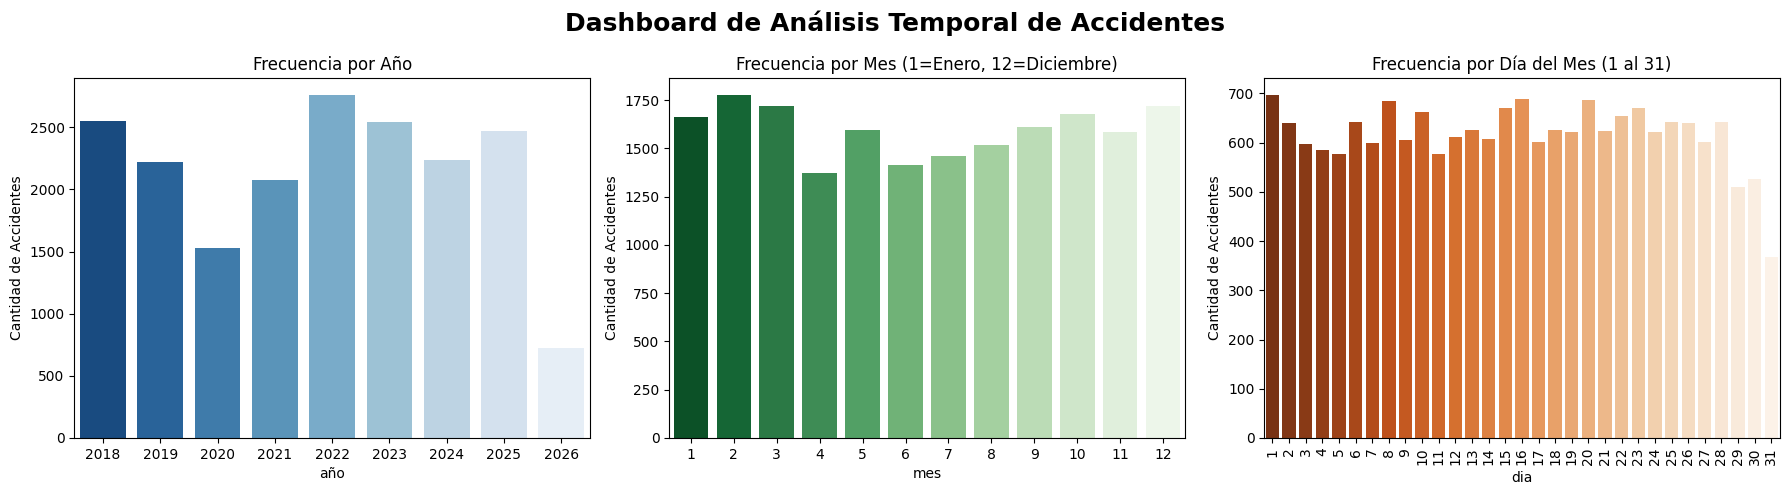

In [ ]:
# Impresión de frecuencias numéricas para mayor exactitud
print("--- Frecuencia de Accidentes por Año ---")
print(df['año'].value_counts().sort_index())

print("\n--- Frecuencia de Accidentes por Mes ---")
print(df['mes'].value_counts().sort_index())

print("\n--- Frecuencia de Accidentes por Día ---")
print(df['dia'].value_counts().sort_index())
print("\n======================================================\n")

# Dashboard Temporal (3 gráficos en 1)
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Dashboard de Análisis Temporal de Accidentes', fontsize=18, fontweight='bold')

# 1. Por Año
sns.countplot(data=df, x='año', ax=ax[0], palette='Blues_r')
ax[0].set_title('Frecuencia por Año')
ax[0].set_ylabel('Cantidad de Accidentes')

# 2. Por Mes
sns.countplot(data=df, x='mes', ax=ax[1], palette='Greens_r')
ax[1].set_title('Frecuencia por Mes (1=Enero, 12=Diciembre)')
ax[1].set_ylabel('Cantidad de Accidentes')

# 3. Por Día del Mes
sns.countplot(data=df, x='dia', ax=ax[2], palette='Oranges_r')
ax[2].set_title('Frecuencia por Día del Mes (1 al 31)')
ax[2].set_ylabel('Cantidad de Accidentes')
ax[2].tick_params(axis='x', rotation=90)

plt.tight_layout()
plt.show()

> Al consolidar estas 3 variables y sus frecuencias numéricas, obtenemos una radiografía exacta del comportamiento temporal de la accidentalidad vial en la ciudad:
> 1. **Por Año:** Se observa que el año con mayor cantidad de siniestros fue el **2022**, marcando un claro pico histórico post-pandemia tras la fuerte y esperada caída registrada en el **2020** (confinamiento). La reducida cifra del **2026** indica claramente que corresponde a datos incompletos del año en curso o posibles rezagos de registro.
> 2. **Por Mes:** Los meses más críticos y de mayor accidentalidad corresponden abrumadoramente al primer trimestre (**Enero, Febrero y Marzo**), coincidiendo de forma directa con la temporada de pre-carnavales y carnavales en la ciudad, donde el flujo vehicular, el consumo de alcohol y la imprudencia vial tienden a dispararse.
> 3. **Por Día del mes:** El comportamiento diario muestra que los siniestros presentan repuntes altísimos en los días **1, 8, 16 y 20**. Estos picos demuestran una clara relación con las dinámicas comerciales y laborales (pago de nóminas a inicio y mitad de mes, quincenas), fechas en las que se maximiza el tráfico por actividades de consumo.
>
> Como hallazgo crítico de Data Quality derivado de este EDA, se determinó que la hora exacta de los incidentes no está siendo capturada o migrada correctamente por el sistema central (marcando todo por defecto a las 00:00), lo que obligó a su descarte técnico, evidenciando una importante oportunidad de mejora para la entidad que administra estos Datos Abiertos.

---

## 6. Conclusiones Generales del Análisis

> A partir del exhaustivo análisis exploratorio (EDA) y la depuración ejecutada sobre el conjunto de datos de accidentalidad, se concluyen los siguientes hallazgos generales:
>
> 1. **Vulnerabilidad Demográfica:** Existe una brecha abismal en la siniestralidad por género y edad. Los hombres jóvenes (con un promedio de edad de 35 años y un pico crítico a los 24 años) representan el perfil inmensamente mayoritario y más expuesto en las vías de la ciudad.
> 2. **Severidad e Impacto en Salud Pública:** El 98.2% de las víctimas resultan heridas y la gran mayoría de incidentes son individuales (1 víctima). Sin embargo, el 1.8% de fatalidades y los eventos atípicos detectados en los boxplots (accidentes masivos de hasta 7 víctimas) demuestran que la siniestralidad vial genera una carga constante y altísima sobre la red de clínicas, hospitales y urgencias.
> 3. **Patrones Temporales y Socio-culturales:** La accidentalidad no es un fenómeno aleatorio, sino que obedece al comportamiento de la ciudad. Los siniestros se disparan dramáticamente durante el primer trimestre del año (época de pre-carnavales y carnavales) y sufren fuertes repuntes en los días de quincena o inicio de mes (días 1, 16), vinculados al aumento del tráfico por consumo y ocio.
> 4. **Importancia del Data Quality:** Este proyecto comprobó el valor real de aplicar Minería de Datos inicial. Gracias a las técnicas de limpieza y visualización descriptiva, se lograron aislar errores de digitación severos (ej. edades reportadas como '2026' o mayores a 120 años) e identificar graves falencias sistémicas en la fuente gubernamental (horas capturadas siempre a las 00:00), garantizando que estas conclusiones sean completamente veraces y libres de sesgo.
